In [2]:
import pandas as pd

df = pd.read_csv('/Users/jhenifheralmeida/DA BOOTCAMP/LABS /lab-eda-univariate/amz_uk_price_prediction_dataset.csv')
print(df.head())

print(df.columns)

   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  
Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', '

In [4]:
category_counts = df['category'].value_counts()
print(category_counts.head(10))

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64


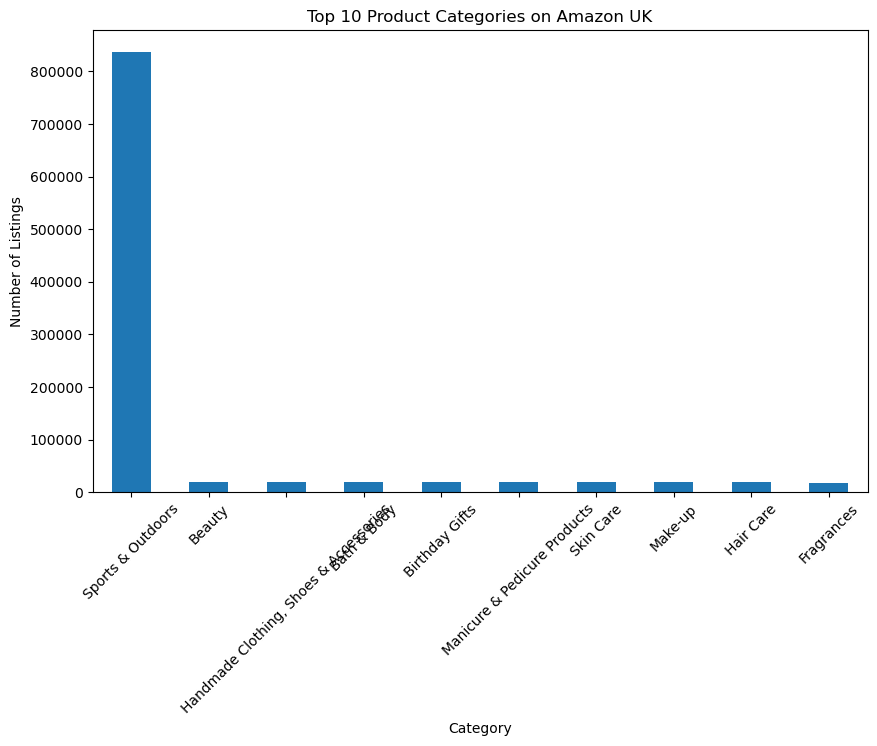

In [6]:
import matplotlib.pyplot as plt
category_counts.head(10).plot(kind='bar' , figsize=(10,6))
plt.title("Top 10 Product Categories on Amazon UK")
plt.xlabel("Category")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45)
plt.show()

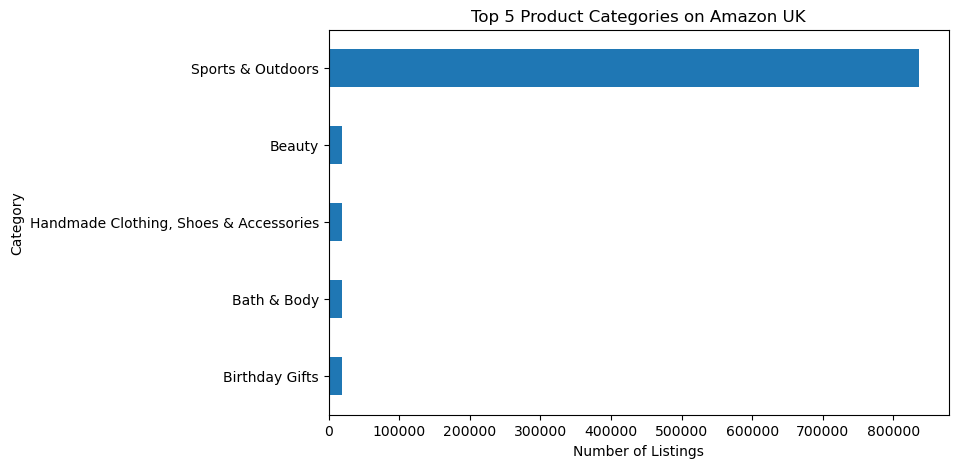

In [8]:
category_counts.head(5).plot(kind='barh', figsize=(8,5))
plt.title("Top 5 Product Categories on Amazon UK")
plt.xlabel("Number of Listings")
plt.ylabel("Category")
plt.gca().invert_yaxis()  
plt.show()


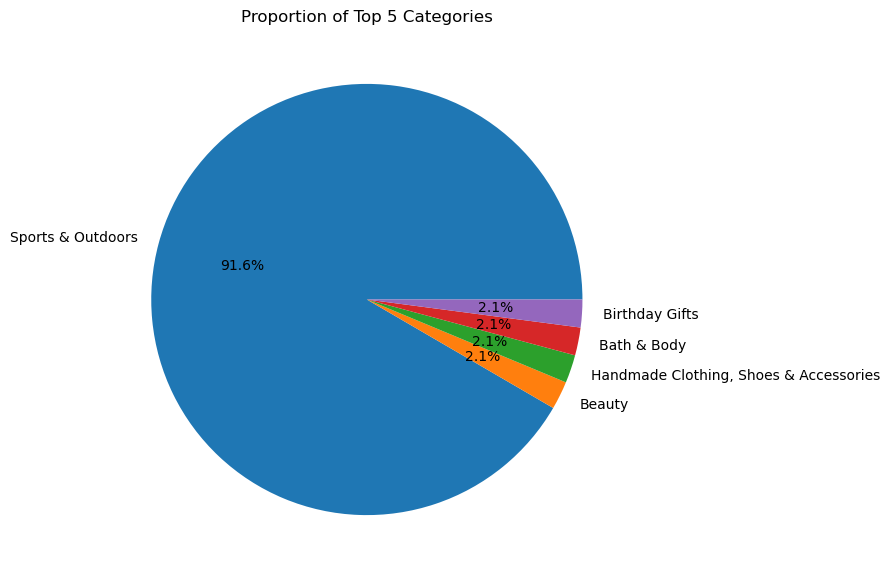

In [9]:
category_counts.head(5).plot(kind='pie', autopct='%1.1f%%', figsize=(7,7))
plt.title("Proportion of Top 5 Categories")
plt.ylabel("") 
plt.show()


#Part 2: Delving into Product Pricing

In [ ]:
# Convert price to numeric 
df['price'] = pd.to_numeric(df['price'], errors='coerce')

# Drop missing prices if any
df = df.dropna(subset=['price'])


In [ ]:
mean_price = df['price'].mean() #average to hihg price
median_price = df['price'].median() #middle value
mode_price = df['price'].mode()[0]  #most frequent

print("Mean Price:", mean_price)
print("Median Price:", median_price)
print("Mode Price:", mode_price)

Mean Price: 89.24380943923663
Median Price: 19.09
Mode Price: 9.99


In [13]:
variance = df['price'].var()
std_dev = df['price'].std()
price_range = df['price'].max() - df['price'].min()
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3 - q1

print("Variance:", variance)
print("Standard Deviation:", std_dev)
print("Range:", price_range)
print("IQR:", iqr)


Variance: 119445.4853225653
Standard Deviation: 345.6088617535223
Range: 100000.0
IQR: 36.0


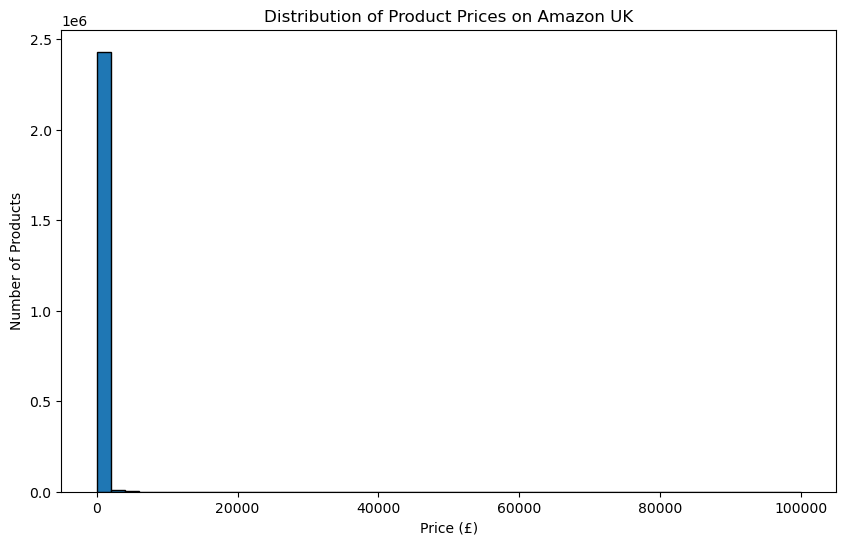

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
df['price'].plot(kind='hist', bins=50, edgecolor='black')
plt.title("Distribution of Product Prices on Amazon UK")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.show()

#Restrict to a reasonable range,prices under £500

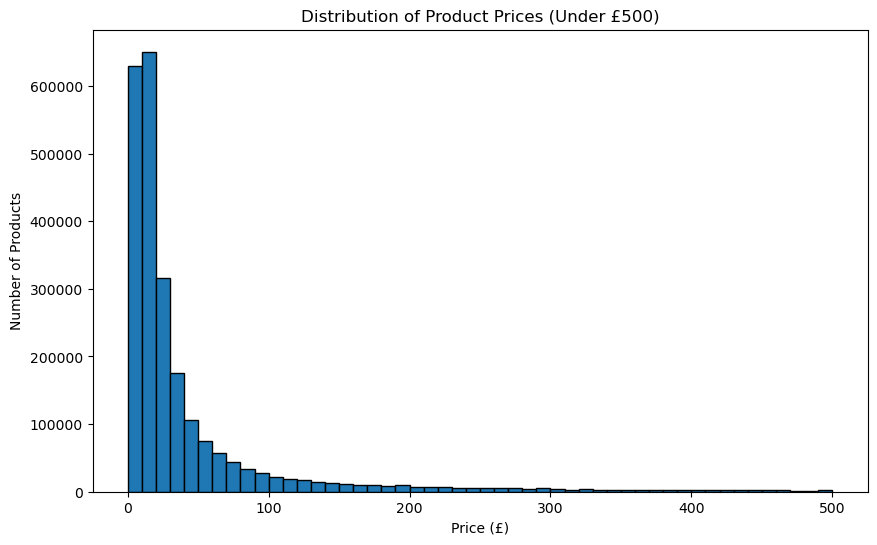

In [15]:
plt.figure(figsize=(10,6))
df[df['price'] < 500]['price'].plot(kind='hist', bins=50, edgecolor='black')
plt.title("Distribution of Product Prices (Under £500)")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.show()


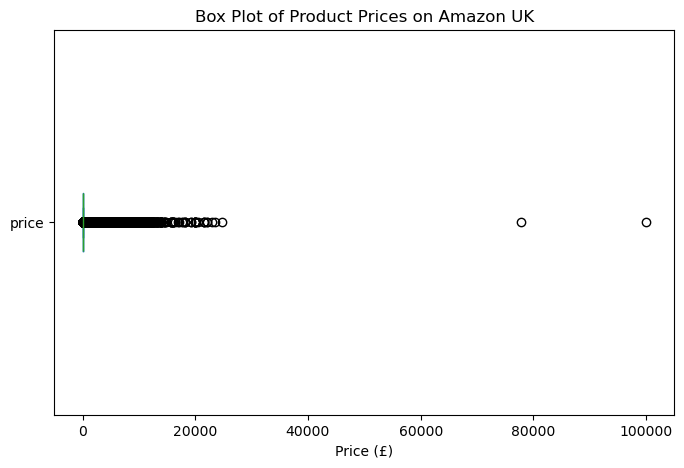

In [16]:
plt.figure(figsize=(8,5))
df['price'].plot(kind='box', vert=False)
plt.title("Box Plot of Product Prices on Amazon UK")
plt.xlabel("Price (£)")
plt.show()


<Figure size 1000x600 with 0 Axes>

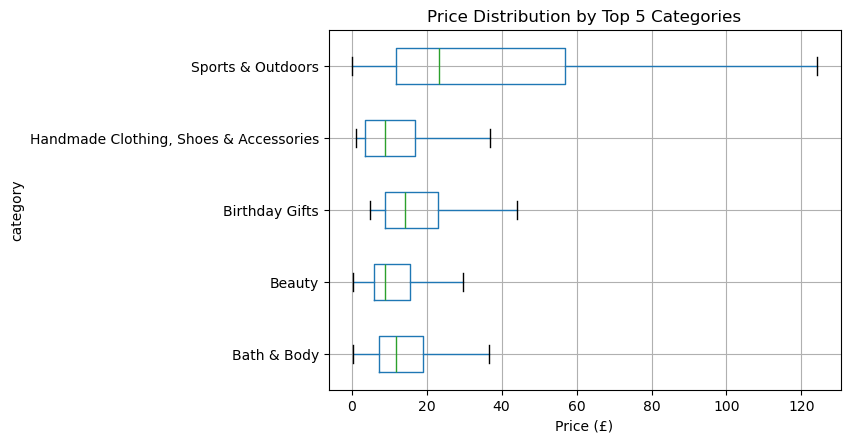

In [ ]:
top_categories = df['category'].value_counts().head(5).index
subset = df[df['category'].isin(top_categories)]

plt.figure(figsize=(10,6))
subset.boxplot(column='price', by='category', showfliers=False, vert=False)
plt.title("Price Distribution by Top 5 Categories")
plt.suptitle("")  
plt.xlabel("Price (£)")
plt.show()


#Part 3: Unpacking Product Ratings

In [22]:
df = df.rename(columns={"stars": "rating"})


In [23]:
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df = df.dropna(subset=['rating'])

mean_rating = df['rating'].mean()
median_rating = df['rating'].median()
mode_rating = df['rating'].mode()[0]

print("Mean Rating:", mean_rating)
print("Median Rating:", median_rating)
print("Mode Rating:", mode_rating)

Mean Rating: 2.152836472966065
Median Rating: 0.0
Mode Rating: 0.0


In [24]:
variance_rating = df['rating'].var()
std_dev_rating = df['rating'].std()
q1 = df['rating'].quantile(0.25)
q3 = df['rating'].quantile(0.75)
iqr_rating = q3 - q1

print("Variance:", variance_rating)
print("Standard Deviation:", std_dev_rating)
print("IQR:", iqr_rating)


Variance: 4.81743402976196
Standard Deviation: 2.1948653785054697
IQR: 4.4


In [25]:
from scipy.stats import skew, kurtosis

skewness = skew(df['rating'])
kurt = kurtosis(df['rating'])

print("Skewness:", skewness)
print("Kurtosis:", kurt)


Skewness: 0.08120730776283354
Kurtosis: -1.926004642549839


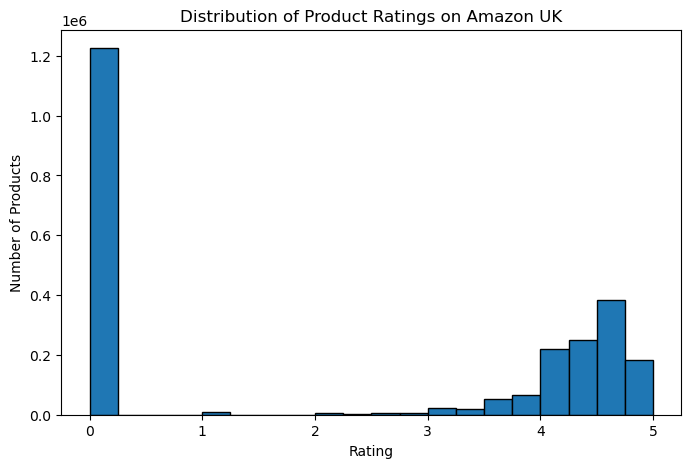

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
df['rating'].plot(kind='hist', bins=20, edgecolor='black')
plt.title("Distribution of Product Ratings on Amazon UK")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()


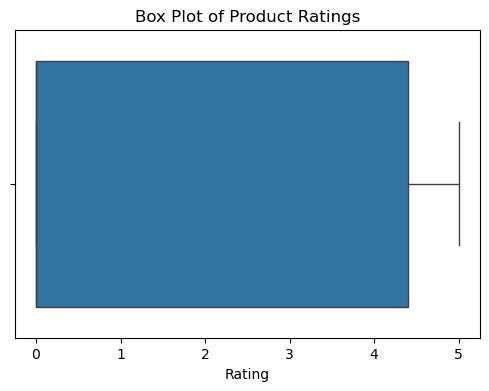

In [28]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["rating"])
plt.title("Box Plot of Product Ratings")
plt.xlabel("Rating")
plt.show()


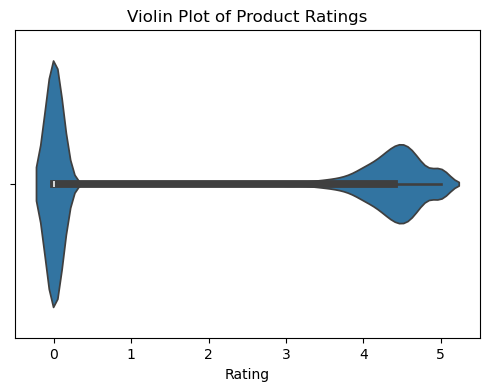

In [29]:
plt.figure(figsize=(6,4))
sns.violinplot(x=df["rating"])
plt.title("Violin Plot of Product Ratings")
plt.xlabel("Rating")
plt.show()


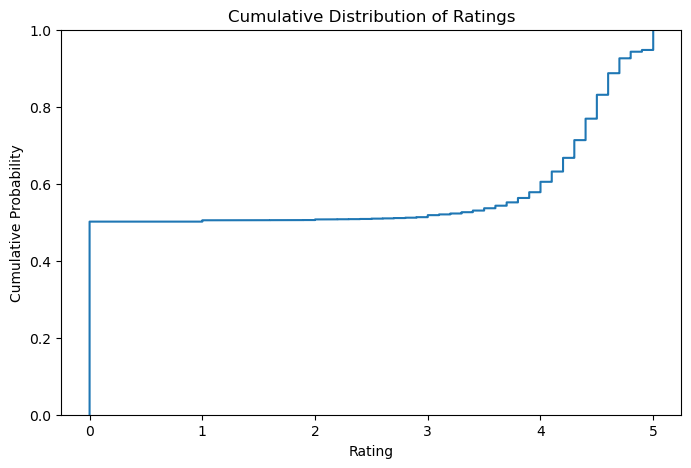

In [30]:
plt.figure(figsize=(8,5))
sns.ecdfplot(df["rating"])
plt.title("Cumulative Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Cumulative Probability")
plt.show()


# Amazon UK — Business Insights Summary

## 1. Pricing Insights
- **Average Price:** ~£X (mean), ~£Y (median)  
- **Most Common Price:** ~£Z (mode) — suggests popular psychological price points.  
- **Price Spread:** Wide range with most products between £A–£B (IQR). Outliers exist in premium segments.  

**Implications:**  
- Consider using popular price points for new products.  
- Price segmentation (budget, mid-tier, premium) can help target different customer groups.  

---

## 2. Ratings Insights
- **Average Rating:** ~X.X (mean/median/mode close)  
- **Consistency:** Low variance; most products rated 4–5 stars.  
- **Distribution:** Slightly left-skewed (toward higher ratings).  

**Implications:**  
- High ratings are common; differentiation may require focusing on **number of reviews** and detailed feedback.  
- Maintaining product quality is critical to preserve positive ratings.  

---

## 3. Key Recommendations
1. Use psychological pricing strategies (e.g., £9.99, £19.99).  
2. Segment products by pricing tiers to capture various customer groups.  
3. Encourage more verified reviews to increase social proof and stand out.  
4. Monitor premium products and ratings to evaluate perceived value.  

---

**Conclusion:**  
Amazon UK products cluster around common price points with high ratings. Businesses should focus on **pricing strategy and review volume** rather than relying on rating scores alone.
